<img src="Bilder/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

# 2. Explorative Datenanalyse

Beschreiben wie bei der explorativen Datenanalyse vorgegangen wurde...
zuerst wird Datenanalyse durchgeführt auf die s&p500_1min_2024_10_25.csv Daten
dann werden daraus Paare gebildet
dann werden Daten zu den Paaren gesammelt
darauf wird dann eine Datenanalyse durchgeführt
zum Schluss Fazit

In [13]:
## Bibliotheken & Daten laden

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

plt.style.use("seaborn-v0_8-whitegrid")

df = pd.read_csv("Daten/sp500_1min_2024-10-25.csv", parse_dates=["datetime"])

print("Anzahl Zeilen:", len(df))
print("Anzahl Ticker:", df['symbol'].nunique())
df.head()

Anzahl Zeilen: 196667
Anzahl Ticker: 503


,symbol,datetime,open,high,low,close,volume
0,MMM,2025-11-07 14:30:00,163.910004,163.929993,163.389999,163.820007,45015.0
1,MMM,2025-11-07 14:31:00,163.910004,163.979996,163.910004,163.979996,2321.0
2,MMM,2025-11-07 14:32:00,163.889999,163.910004,163.699997,163.699997,1533.0
3,MMM,2025-11-07 14:33:00,163.934998,164.179993,163.429993,163.429993,3947.0
4,MMM,2025-11-07 14:34:00,163.429993,163.990005,163.419998,163.839996,4934.0


In [14]:
## Überblick & Datenqualität

# Basisinformationen
df.info()

# Prüfe auf fehlende Werte
missing = df.isna().sum()
print("\nFehlende Werte pro Spalte:")
print(missing[missing > 0])

# Anzahl Zeilen pro Aktie
counts = df.groupby("symbol")["datetime"].count().sort_values(ascending=False)
print("\nDatenpunkte pro Aktie:")
print(counts.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196667 entries, 0 to 196666
Data columns (total 7 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   symbol    196667 non-null  object        
 1   datetime  196667 non-null  datetime64[ns]
 2   open      187829 non-null  float64       
 3   high      187829 non-null  float64       
 4   low       187829 non-null  float64       
 5   close     187829 non-null  float64       
 6   volume    187829 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 10.5+ MB

Fehlende Werte pro Spalte:
open      8838
high      8838
low       8838
close     8838
volume    8838
dtype: int64

Datenpunkte pro Aktie:
count    503.000000
mean     390.988072
std        0.188981
min      387.000000
25%      391.000000
50%      391.000000
75%      391.000000
max      391.000000
Name: datetime, dtype: float64


Es gibt 281 Aktien mit mindestens einem fehlenden Wert.

Top 15 betroffene Ticker (mit Anzahl fehlender Zeilen):
symbol
NVR     296
ERIE    249
NDSN    239
GWW     174
CINF    160
PKG     158
SBAC    153
TPL     146
UHS     139
GL      137
AVY     121
AIZ     119
LDOS    115
NWS     113
ALGN    111
dtype: int64


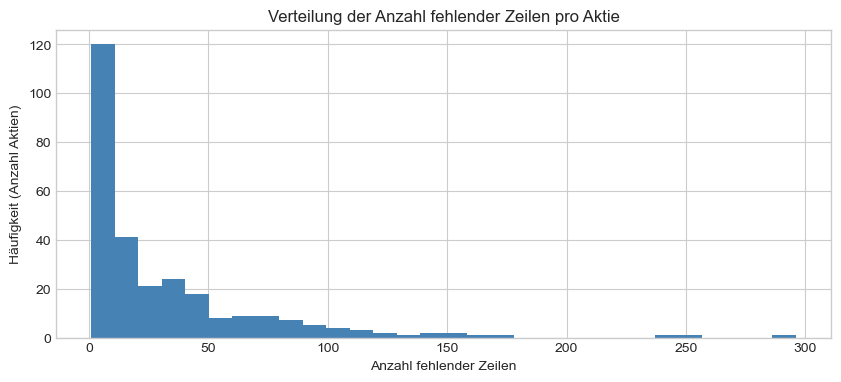

In [15]:
## Inspektion der fehlenden Daten

# Alle Zeilen mit mindestens einem NaN
missing_rows = df[df.isna().any(axis=1)]

# Nach Ticker gruppieren und zählen
missing_by_symbol = missing_rows.groupby("symbol").size().sort_values(ascending=False)
print(f"Es gibt {len(missing_by_symbol)} Aktien mit mindestens einem fehlenden Wert.\n")
print("Top 15 betroffene Ticker (mit Anzahl fehlender Zeilen):")
print(missing_by_symbol.head(15))

# Visualisierung: wie stark sind die Lücken verteilt?
plt.figure(figsize=(10,4))
missing_by_symbol.plot(kind="hist", bins=30, color="steelblue")
plt.title("Verteilung der Anzahl fehlender Zeilen pro Aktie")
plt.xlabel("Anzahl fehlender Zeilen")
plt.ylabel("Häufigkeit (Anzahl Aktien)")
plt.show()

In [ ]:
df['time'] = df['datetime'].dt.time
df[df['open'].isna()]['time'].value_counts().head(10)

18:06:00    54
18:21:00    54
17:58:00    52
18:19:00    52
18:04:00    50
18:10:00    50
17:44:00    50
17:34:00    49
18:01:00    49
17:36:00    48
Name: time, dtype: int64

           n_gaps  avg_gap_len  max_gap_len  avg_rel_price_change  \
count  503.000000   503.000000   503.000000            503.000000   
mean    12.733598     1.208963     1.874751             -0.000009   
std     20.616122     1.102512     2.419669              0.000315   
min      0.000000     0.000000     0.000000             -0.003567   
25%      0.000000     0.000000     0.000000             -0.000017   
50%      1.000000     2.000000     2.000000              0.000000   
75%     17.000000     2.090909     3.000000              0.000040   
max     88.000000     5.417910    27.000000              0.001742   

       max_rel_price_change  
count            503.000000  
mean               0.001386  
std                0.002089  
min                0.000000  
25%                0.000000  
50%                0.000397  
75%                0.002284  
max                0.020662  


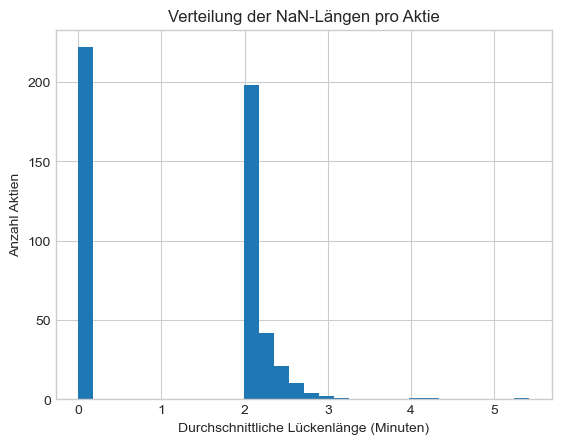

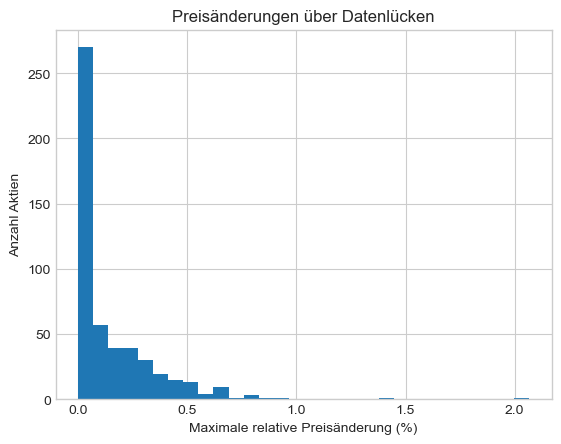

In [ ]:
def analyse_nan_luecken(df):
    """Analysiert NaN-Lücken pro Aktie."""
    results = []
    normal_step = pd.Timedelta(minutes=1)

    for ticker, data in df.groupby("symbol"):
        data = data.sort_values("datetime").reset_index(drop=True)
        is_nan = data["close"].isna()

        if not is_nan.any():
            results.append({
                "symbol": ticker,
                "n_gaps": 0,
                "avg_gap_len": 0,
                "max_gap_len": 0,
                "avg_rel_price_change": 0,
                "max_rel_price_change": 0,
            })
            continue

        # Indizes der NaNs
        nan_idx = np.where(is_nan)[0]

        # Finde aufeinanderfolgende NaN-Blöcke
        gap_blocks = np.split(nan_idx, np.where(np.diff(nan_idx) > 1)[0] + 1)

        gap_info = []
        for block in gap_blocks:
            gap_start_idx = block[0] - 1
            gap_end_idx = block[-1] + 1

            if gap_start_idx < 0 or gap_end_idx >= len(data):
                continue  # keine gültigen Vergleichswerte

            t_before = data.loc[gap_start_idx, "datetime"]
            t_after = data.loc[gap_end_idx, "datetime"]
            close_before = data.loc[gap_start_idx, "close"]
            close_after = data.loc[gap_end_idx, "close"]

            if pd.isna(close_before) or pd.isna(close_after):
                continue

            gap_len = (t_after - t_before) / normal_step  # Minuten
            rel_change = (close_after - close_before) / close_before

            gap_info.append((gap_len, rel_change))

        if gap_info:
            gap_df = pd.DataFrame(gap_info, columns=["gap_len", "rel_change"])
            results.append({
                "symbol": ticker,
                "n_gaps": len(gap_df),
                "avg_gap_len": gap_df["gap_len"].mean(),
                "max_gap_len": gap_df["gap_len"].max(),
                "avg_rel_price_change": gap_df["rel_change"].mean(),
                "max_rel_price_change": gap_df["rel_change"].abs().max(),
            })
        else:
            results.append({
                "symbol": ticker,
                "n_gaps": 0,
                "avg_gap_len": 0,
                "max_gap_len": 0,
                "avg_rel_price_change": 0,
                "max_rel_price_change": 0,
            })

    return pd.DataFrame(results)

nan_gaps = analyse_nan_luecken(df)
print(nan_gaps.describe())
nan_gaps.sort_values("n_gaps", ascending=False).head(15)

plt.hist(nan_gaps["avg_gap_len"], bins=30)
plt.xlabel("Durchschnittliche Lückenlänge (Minuten)")
plt.ylabel("Anzahl Aktien")
plt.title("Verteilung der NaN-Längen pro Aktie")
plt.show()

plt.hist(nan_gaps["max_rel_price_change"] * 100, bins=30)
plt.xlabel("Maximale relative Preisänderung (%)")
plt.ylabel("Anzahl Aktien")
plt.title("Preisänderungen über Datenlücken")
plt.show()